# MultiIndex and Advanced Data Structures in Pandas

Many datasets have more than one natural key: **country and year**, **store and day**, **sensor and timestamp**. A **MultiIndex** uses several levels as row (or column) labels. Closely related are the two table shapes: **long** (one row per observation) and **wide** (one column per category), and the tools to convert between them.

**After this lesson you can:**

1. Create a MultiIndex and select with `loc`, `xs` and `pd.IndexSlice`.
2. Reshape between long and wide with `stack`/`unstack`, `pivot` and `melt`.
3. Aggregate by index level.
4. Choose between long and wide formats for analysis, plotting and storage.

**Data:** Gapminder (63 countries, 1955–2005 in 5-year steps): population, life expectancy and fertility (CC BY 4.0).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

gap = pd.read_json(datasets.fetch("gapminder.json"))
REGIONS = {0: "South Asia", 1: "Europe & Central Asia", 2: "Sub-Saharan Africa", 3: "Americas",
           4: "East Asia & Pacific", 5: "Middle East & North Africa"}
gap["region"] = gap["cluster"].map(REGIONS)
print(gap.shape, "| years:", sorted(gap["year"].unique()))
gap.head(3)

(693, 7) | years: [np.int64(1955), np.int64(1960), np.int64(1965), np.int64(1970), np.int64(1975), np.int64(1980), np.int64(1985), np.int64(1990), np.int64(1995), np.int64(2000), np.int64(2005)]


,year,country,cluster,pop,life_expect,fertility,region
0,1955,Afghanistan,0,8891209,30.332,7.7,South Asia
1,1960,Afghanistan,0,9829450,31.997,7.7,South Asia
2,1965,Afghanistan,0,10997885,34.020,7.7,South Asia


## 1. Create a MultiIndex

`set_index([level1, level2])` creates a MultiIndex. Sort it (`sort_index`) for fast and predictable selection.

In [2]:
g = gap.set_index(["country", "year"]).sort_index()
print(g.index.names, "| levels:", g.index.nlevels, "| unique countries:", g.index.get_level_values("country").nunique())
g.head(4)

['country', 'year'] | levels: 2 | unique countries: 63


cluster       pop  life_expect  fertility      region
country     year                                                       
Afghanistan 1955        0   8891209       30.332        7.7  South Asia
            1960        0   9829450       31.997        7.7  South Asia
            1965        0  10997885       34.020        7.7  South Asia
            1970        0  12430623       36.088        7.7  South Asia

## 2. Select from a MultiIndex

| Selection | Code |
| :--- | :--- |
| one outer label | `g.loc["Turkey"]` |
| one full key | `g.loc[("Turkey", 2005)]` |
| one inner label for all outer labels | `g.xs(2005, level="year")` |
| ranges on several levels | `g.loc[pd.IndexSlice["China":"India", 1990:2005], :]` |

In [3]:
idx = pd.IndexSlice
print(g.loc["Turkey", ["life_expect", "fertility"]].tail(3), "\n")
print("Turkey 2005:", g.loc[("Turkey", 2005), "life_expect"], "years")
latest = g.xs(2005, level="year")
print(f"\n2005: {len(latest)} countries, highest life expectancy: {latest['life_expect'].idxmax()} ({latest['life_expect'].max():.1f})")
g.loc[idx[["China", "India", "Japan"], 1995:2005], ["pop", "life_expect"]]

      life_expect  fertility
year                        
1995       68.835      2.574
2000       70.845      2.230
2005       71.777      2.143 

Turkey 2005: 71.777 years

2005: 63 countries, highest life expectancy: Japan (82.6)


pop  life_expect
country year                         
China   1995  1204855000       70.426
        2000  1262645000       72.028
        2005  1303182268       72.961
India   1995   927000000       61.765
        2000  1007702000       62.879
        2005  1080264388       64.698
Japan   1995   125341354       80.690
        2000   126699784       82.000
        2005   127417244       82.603

## 3. Long and Wide: `unstack`, `stack`, `pivot`, `melt`

- **Long** format: one row per (country, year, variable) observation. Best for grouping, filtering, plotting libraries and databases ("tidy data").
- **Wide** format: one column per year (or per country). Best for reading, comparing and some calculations (for example growth between two columns).

In [4]:
wide = g["life_expect"].unstack("year")                  # rows: countries, columns: years
print("wide:", wide.shape)
print(wide.loc[["Turkey", "Brazil", "Nigeria"], [1955, 1980, 2005]], "\n")

back = wide.stack()                                      # wide -> long Series with a MultiIndex
print("stack gives back the long series:", back.equals(g["life_expect"]))

long = gap.melt(id_vars=["country", "year"], value_vars=["life_expect", "fertility"], var_name="indicator")
print("\nmelt -> long table:", long.shape)
print(long.head(3))
pivoted = long.pivot(index=["country", "year"], columns="indicator", values="value")
print("\npivot -> back to one column per indicator:", pivoted.shape)

wide: (63, 11)
year       1955    1980    2005
country                        
Turkey   48.079  61.036  71.777
Brazil   53.285  63.336  72.390
Nigeria  37.802  45.826  46.859 

stack gives back the long series: True

melt -> long table: (1386, 4)
       country  year    indicator   value
0  Afghanistan  1955  life_expect  30.332
1  Afghanistan  1960  life_expect  31.997
2  Afghanistan  1965  life_expect  34.020

pivot -> back to one column per indicator: (693, 2)


## 4. Aggregate by Level and by Group

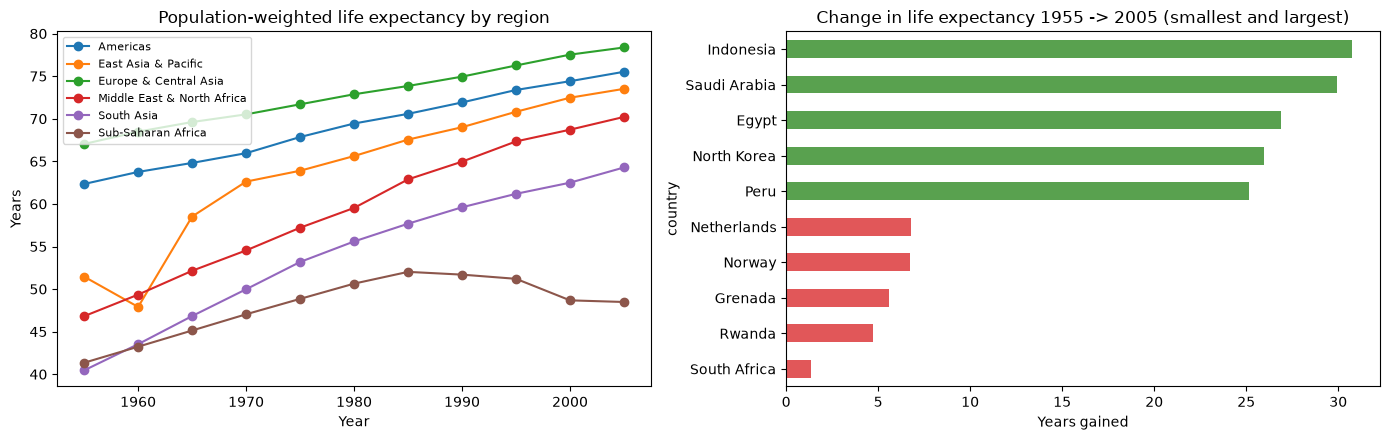

mean over countries per year (groupby level): {1955: 57.6, 2005: 72.9}


In [5]:
pop_weighted = (gap.assign(w=gap["life_expect"] * gap["pop"])
                .groupby(["region", "year"])
                .agg(w=("w", "sum"), pop=("pop", "sum")))
pop_weighted["life_expect"] = pop_weighted["w"] / pop_weighted["pop"]
by_region = pop_weighted["life_expect"].unstack("region")

gains = (wide[2005] - wide[1955]).sort_values()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
by_region.plot(ax=ax1, marker="o")
ax1.set(title="Population-weighted life expectancy by region", ylabel="Years", xlabel="Year")
ax1.legend(fontsize=8)
pd.concat([gains.head(5), gains.tail(5)]).plot.barh(ax=ax2, color=["#E15759"] * 5 + ["#59A14F"] * 5)
ax2.set(title="Change in life expectancy 1955 -> 2005 (smallest and largest)", xlabel="Years gained")
plt.tight_layout()
plt.show()
print("mean over countries per year (groupby level):", g["life_expect"].groupby(level="year").mean().round(1).iloc[[0, -1]].to_dict())

A simple mean over countries treats small and large countries equally; the population-weighted mean answers "how long does the average person live?". Decide which question you are asking before you aggregate.

## 5. MultiIndex Columns

Columns can also have levels, for example after a `pivot_table` with several values or an `agg` with several functions. Flatten them with a list comprehension when you need simple names.

In [6]:
summary = gap.groupby("region").agg({"life_expect": ["min", "max"], "fertility": ["min", "max"]})
print(summary.round(1), "\n")
summary.columns = [f"{var}_{stat}" for var, stat in summary.columns]
print(list(summary.columns))

                           life_expect       fertility     
                                   min   max       min  max
region                                                     
Americas                          40.7  80.7       1.5  7.6
East Asia & Pacific               39.9  82.6       0.9  7.1
Europe & Central Asia             48.1  81.8       1.2  6.6
Middle East & North Africa        42.9  80.7       2.0  7.3
South Asia                        30.3  65.5       2.8  8.0
Sub-Saharan Africa                23.6  61.9       2.6  8.5 

['life_expect_min', 'life_expect_max', 'fertility_min', 'fertility_max']


*Insight: Keep data in long format for storage, grouping and plotting, and create wide views (`unstack`, `pivot`) for reading and comparison. Use a sorted MultiIndex when you repeatedly select by several keys.*

## Real-World Use Case or Analogy

A MultiIndex is like an **address**: country, city, street. You can ask for everything in one country, for one exact address, or for "every street called Atatürk Caddesi in any city" (`xs`). Long vs wide is like a **ledger** (one line per transaction) vs a **summary sheet** (one column per month).

Economists work with panel data (country × year), retailers with store × day, IoT teams with sensor × timestamp. Statistical models usually need the long format; Excel reports usually need the wide one.